# Naive Bayes Classification - Titanic Dataset
Proyek klasifikasi Machine Learning untuk memprediksi kelangsungan hidup penumpang (*Survived*) pada dataset Titanic menggunakan algoritma **Naive Bayes (Gaussian Naive Bayes)**.

Notebook ini disusun berdasarkan alur kerja tugas sebelumnya (`knn.ipynb`), mencakup tahapan:
1. **Importing the libraries** (Pustaka yang digunakan)
2. **Importing the dataset & EDA** (Pemeriksaan awal data Titanic)
3. **Data Preprocessing & Cleaning** (Penanganan missing values, seleksi fitur, & encoding data kategorikal)
4. **Splitting the dataset** (Pemisahan Training set & Test set)
5. **Feature Scaling** (Standardisasi fitur dengan StandardScaler)
6. **Training the Naive Bayes model** (Pelatihan model Gaussian Naive Bayes)
7. **Predicting the Test set results** (Prediksi kelas & probabilitas data uji)
8. **Making the Confusion Matrix & Evaluation** (Evaluasi model, Confusion Matrix heatmap, & Classification Report)
9. **Analisis Probabilitas & Kurva ROC-AUC** (Evaluasi kemampuan diskriminasi probabilitas model)
10. **Visualising the Decision Boundary** (Visualisasi batas keputusan 2D pada data latih dan data uji)

## 1. Importing the libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_curve, roc_auc_score
from matplotlib.colors import ListedColormap

## 2. Importing the dataset & Exploratory Data Analysis (EDA)
Membaca dataset Titanic dan melakukan inspeksi struktur data awal.

In [2]:
dataset = pd.read_csv('titanic.csv')
dataset.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Menampilkan informasi ringkas dan tipe data setiap kolom
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
# Memeriksa jumlah nilai yang hilang (missing values) pada tiap kolom
dataset.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## 3. Data Preprocessing
Tahap pembersihan dan persiapan data sebelum pemodelan:
- **Penanganan Missing Values**:
  - Kolom `Age` diisi dengan median usia.
  - Kolom `Embarked` diisi dengan modus (pelabuhan yang paling sering muncul).
- **Seleksi Fitur (Feature Selection)**:
  - Kolom `PassengerId`, `Name`, dan `Ticket` dihapus karena bersifat unik/identitas dan tidak relevan untuk prediksi.
  - Kolom `Cabin` dihapus karena sebagian besar datanya (>77%) hilang (*missing*).
- **Encoding Data Kategorikal**:
  - Kolom `Sex` diubah menjadi biner (0 untuk *male*, 1 untuk *female*).
  - Kolom `Embarked` di-encode menggunakan *One-Hot Encoding* (`pd.get_dummies`).
- **Pemisahan Fitur ($X$) dan Target ($y$)**:
  - Target: Kolom `Survived` (0 = Tidak Selamat, 1 = Selamat).

In [5]:
# Imputasi missing values
dataset['Age'] = dataset['Age'].fillna(dataset['Age'].median())
dataset['Embarked'] = dataset['Embarked'].fillna(dataset['Embarked'].mode()[0])

# Menghapus kolom yang tidak relevan
df_clean = dataset.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

# Encoding variabel kategorikal
df_clean['Sex'] = df_clean['Sex'].map({'male': 0, 'female': 1})
df_clean = pd.get_dummies(df_clean, columns=['Embarked'], drop_first=True, dtype=int)

# Tampilkan 5 baris pertama data setelah diproses
df_clean.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,1
1,1,1,1,38.0,1,0,71.2833,0,0
2,1,3,1,26.0,0,0,7.9250,0,1
3,1,1,1,35.0,1,0,53.1000,0,1
4,0,3,0,35.0,0,0,8.0500,0,1


In [6]:
# Memisahkan matriks fitur (X) dan vektor target (y)
X = df_clean.drop(columns=['Survived']).values
y = df_clean['Survived'].values

print("Fitur yang digunakan:", list(df_clean.drop(columns=['Survived']).columns))
print("Bentuk matriks X:", X.shape)
print("Bentuk vektor y:", y.shape)

Fitur yang digunakan: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_Q', 'Embarked_S']
Bentuk matriks X: (891, 8)
Bentuk vektor y: (891,)


In [7]:
# Menampilkan 5 baris pertama dari fitur X
X[:5]

array([[ 3.    ,  0.    , 22.    ,  1.    ,  0.    ,  7.25  ,  0.    ,
         1.    ],
       [ 1.    ,  1.    , 38.    ,  1.    ,  0.    , 71.2833,  0.    ,
         0.    ],
       [ 3.    ,  1.    , 26.    ,  0.    ,  0.    ,  7.925 ,  0.    ,
         1.    ],
       [ 1.    ,  1.    , 35.    ,  1.    ,  0.    , 53.1   ,  0.    ,
         1.    ],
       [ 3.    ,  0.    , 35.    ,  0.    ,  0.    ,  8.05  ,  0.    ,
         1.    ]])

## 4. Splitting the dataset into the Training set and Test set
Membagi data menjadi data latih (*training set*) 75% dan data uji (*test set*) 25% dengan `random_state=0` agar konsisten dengan evaluasi sebelumnya.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

print("Jumlah data latih (X_train):", X_train.shape[0])
print("Jumlah data uji (X_test):", X_test.shape[0])

Jumlah data latih (X_train): 668
Jumlah data uji (X_test): 223


In [9]:
X_train[:5]

array([[ 3.    ,  0.    , 28.    ,  0.    ,  0.    ,  7.8958,  0.    ,
         1.    ],
       [ 3.    ,  1.    , 17.    ,  4.    ,  2.    ,  7.925 ,  0.    ,
         1.    ],
       [ 3.    ,  0.    , 30.    ,  1.    ,  0.    , 16.1   ,  0.    ,
         1.    ],
       [ 3.    ,  0.    , 22.    ,  0.    ,  0.    ,  7.25  ,  0.    ,
         1.    ],
       [ 2.    ,  1.    , 45.    ,  0.    ,  0.    , 13.5   ,  0.    ,
         1.    ]])

## 5. Feature Scaling
Standardisasi fitur menggunakan `StandardScaler` agar distribusi fitur memiliki rata-rata ($\mu=0$) dan varians ($\sigma=1$). Pada Gaussian Naive Bayes, penskalaan fitur membantu kestabilan estimasi distribusi probabilitas Gaussian.

In [10]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [11]:
X_train[:5]

array([[ 0.83012938, -0.72705166, -0.11727262, -0.46037161, -0.47720996,
        -0.48380773, -0.31414043,  0.59809997],
       [ 0.83012938,  1.37541808, -0.96500423,  2.98532288,  1.95619654,
        -0.48323058, -0.31414043,  0.59809997],
       [ 0.83012938, -0.72705166,  0.0368604 ,  0.40105202, -0.47720996,
        -0.32165051, -0.31414043,  0.59809997],
       [ 0.83012938, -0.72705166, -0.57967168, -0.46037161, -0.47720996,
        -0.49657206, -0.31414043,  0.59809997],
       [-0.36497068,  1.37541808,  1.19285805, -0.46037161, -0.47720996,
        -0.37303989, -0.31414043,  0.59809997]])

## 6. Training the Naive Bayes model on the Training set
Melatih model klasifikasi menggunakan algoritma **Gaussian Naive Bayes** (`GaussianNB`).

In [12]:
classifier = GaussianNB()
classifier.fit(X_train, y_train)

# Menampilkan probabilitas prior kelas P(Y=0) dan P(Y=1) dari data latih
print("Prior Probabilities (P(Y=0), P(Y=1)):", classifier.class_prior_)

Prior Probabilities (P(Y=0), P(Y=1)): [0.61377246 0.38622754]


## 7. Predicting the Test set results
Melakukan prediksi kelas target pada data uji (*Test set*).

In [13]:
y_pred = classifier.predict(X_test)

In [14]:
print("Hasil Prediksi (y_pred):")
print(y_pred)
print("\nNilai Sebenarnya (y_test):")
print(y_test)

Hasil Prediksi (y_pred):
[0 0 0 1 1 0 1 1 1 1 0 1 0 1 1 1 0 0 0 0 0 1 0 0 1 1 0 1 1 0 0 1 0 0 0 0 0
 0 0 0 1 0 0 0 1 0 0 1 0 1 0 1 1 0 0 0 0 0 0 0 0 1 1 1 1 0 1 0 1 1 1 0 1 0
 0 0 1 0 0 0 0 0 1 0 0 1 1 1 1 1 0 0 0 1 0 0 1 0 0 1 0 0 0 0 1 1 1 1 0 1 0
 1 0 1 1 1 1 1 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 1 0 0 0 1 0 1 1 1 0 1
 1 0 1 1 1 0 1 0 1 0 1 1 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1 0 1 0 0 1 0 0 0 0 0
 0 1 0 0 1 1 0 1 1 0 1 0 1 0 0 0 1 0 1 0 0 1 0 1 0 0 1 0 1 0 0 0 0 1 1 0 1
 1]

Nilai Sebenarnya (y_test):
[0 0 0 1 1 1 1 1 1 1 0 1 0 1 1 0 0 0 0 1 0 1 0 0 0 1 0 1 1 0 0 1 0 1 0 1 0
 0 0 0 1 0 0 0 1 0 0 1 0 0 1 1 1 0 1 0 0 0 0 1 0 0 1 0 1 0 1 0 1 1 1 1 0 0
 0 1 0 0 0 0 0 1 0 0 0 1 1 1 1 0 0 0 1 1 0 0 1 0 0 1 0 0 0 0 0 1 1 0 0 1 0
 1 1 0 1 1 1 1 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 1
 1 0 0 1 0 0 1 0 0 1 0 1 0 1 1 1 0 0 0 0 0 0 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0
 0 1 0 0 1 0 0 1 1 0 0 0 1 1 0 1 0 0 1 1 0 0 0 1 0 0 1 0 0 0 0 0 1 0 1 0 1
 1]


## 8. Making the Confusion Matrix & Classification Report
Mengevaluasi performa model menggunakan Confusion Matrix, Heatmap Seaborn, dan Classification Report (Precision, Recall, F1-Score).

In [15]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[111  28]
 [ 21  63]]


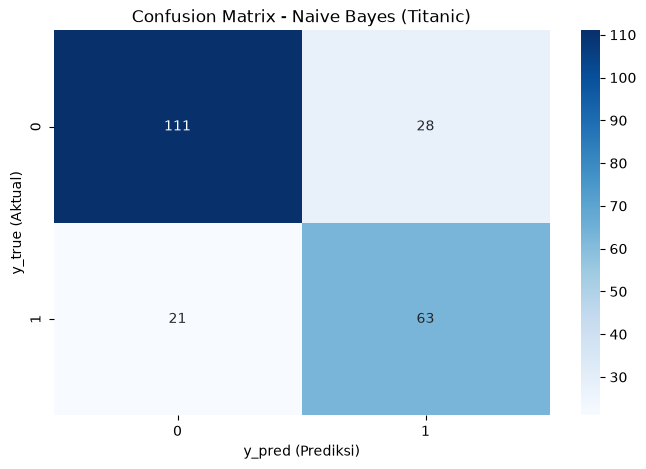

In [16]:
f, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(cm, annot=True, fmt=".0f", cmap='Blues', ax=ax)
plt.title("Confusion Matrix - Naive Bayes (Titanic)")
plt.xlabel("y_pred (Prediksi)")
plt.ylabel("y_true (Aktual)")
plt.show()

In [17]:
print("Akurasi Model:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Akurasi Model: 0.7802690582959642

Classification Report:

              precision    recall  f1-score   support

           0       0.84      0.80      0.82       139
           1       0.69      0.75      0.72        84

    accuracy                           0.78       223
   macro avg       0.77      0.77      0.77       223
weighted avg       0.78      0.78      0.78       223



## 9. Analisis Probabilitas & Kurva ROC-AUC
Salah satu keunggulan utama dari Naive Bayes adalah kemampuannya menghasilkan probabilitas posterior $P(Y=1|X)$. Kita menganalisis kurva ROC (*Receiver Operating Characteristic*) dan skor AUC (*Area Under the Curve*).

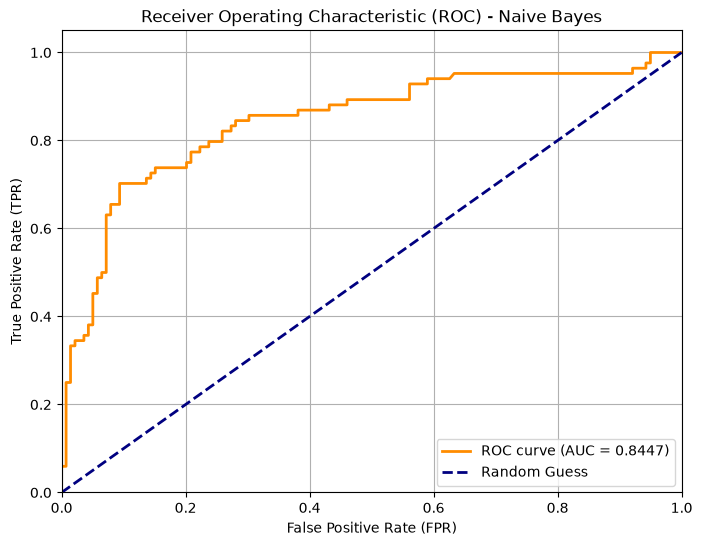

Skor ROC-AUC: 0.8447


In [18]:
# Menghitung probabilitas kelas positif (Survived = 1)
y_proba = classifier.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc_score = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) - Naive Bayes')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print(f"Skor ROC-AUC: {auc_score:.4f}")

## 10. Visualising the Decision Boundary
Memvisualisasikan batas keputusan (*decision boundary*) 2 dimensi Naive Bayes menggunakan dua fitur kontinu representatif (`Age` dan `Fare`), konsisten dengan visualisasi pada tugas K-NN.

In [19]:
# Mengambil 2 fitur: Age dan Fare dari df_clean
X_vis = df_clean[['Age', 'Fare']].values
y_vis = df_clean['Survived'].values

X_train_vis, X_test_vis, y_train_vis, y_test_vis = train_test_split(
    X_vis, y_vis, test_size=0.25, random_state=0
)

sc_vis = StandardScaler()
X_train_vis = sc_vis.fit_transform(X_train_vis)
X_test_vis = sc_vis.transform(X_test_vis)

clf_vis = GaussianNB()
clf_vis.fit(X_train_vis, y_train_vis)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[410.,258.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.61,0.39]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 2)","[[ 0.06,-0.18], [-0.09, 0.29]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 2)","[[0.93,0.42], [1.09,1.79]]"


### Visualising the Training set results

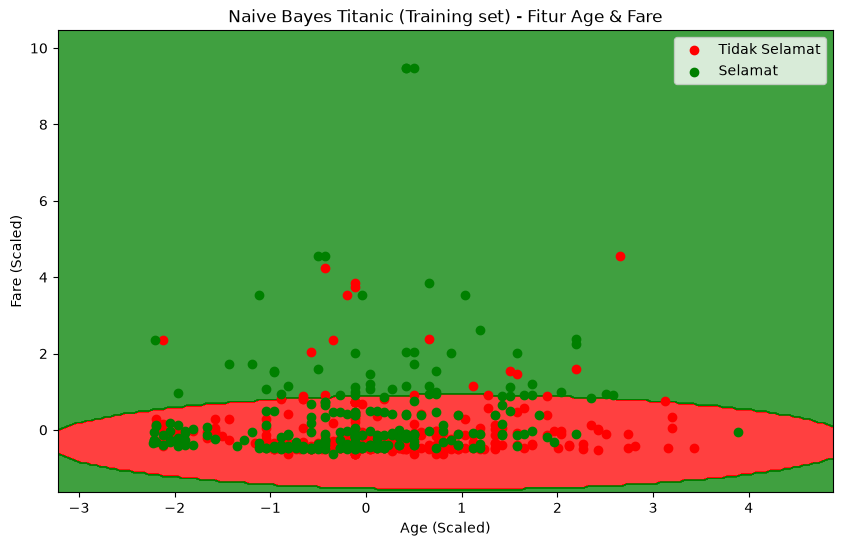

In [20]:
X_set, y_set = X_train_vis, y_train_vis
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 0.05),
                     np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 0.05))
plt.figure(figsize=(10, 6))
plt.contourf(X1, X2, clf_vis.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                color = ListedColormap(('red', 'green'))(i), label = 'Tidak Selamat' if j == 0 else 'Selamat')
plt.title('Naive Bayes Titanic (Training set) - Fitur Age & Fare')
plt.xlabel('Age (Scaled)')
plt.ylabel('Fare (Scaled)')
plt.legend()
plt.show()

### Visualising the Test set results

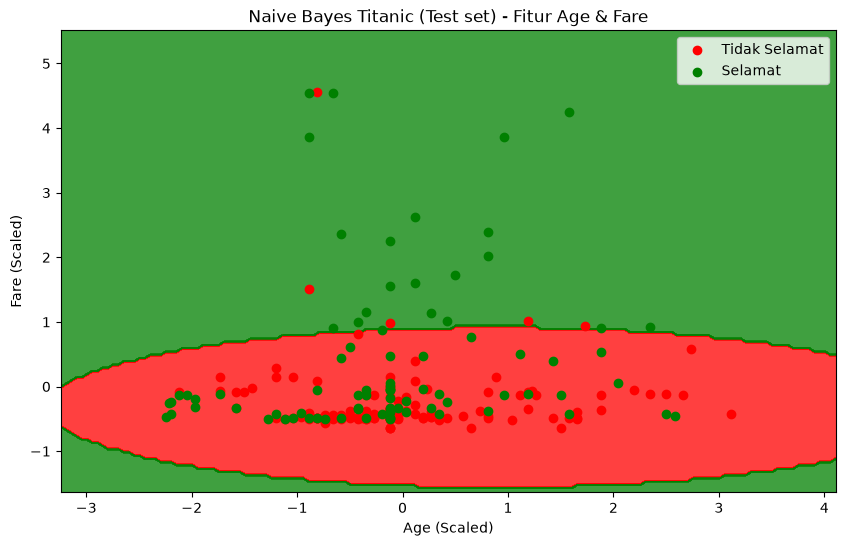

In [21]:
X_set, y_set = X_test_vis, y_test_vis
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 0.05),
                     np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 0.05))
plt.figure(figsize=(10, 6))
plt.contourf(X1, X2, clf_vis.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                color = ListedColormap(('red', 'green'))(i), label = 'Tidak Selamat' if j == 0 else 'Selamat')
plt.title('Naive Bayes Titanic (Test set) - Fitur Age & Fare')
plt.xlabel('Age (Scaled)')
plt.ylabel('Fare (Scaled)')
plt.legend()
plt.show()